Q1. Student Performance and Correlation Analysis
A college wants to identify which academic factors have the strongest relationships with examination marks.

(a) Calculate the Pearson correlation matrix and create an annotated heatmap. Rank all four features by their absolute correlation with Marks, identify the strongest positive and negative relationships, and explain what the coefficients indicate.

(b) Remove the student with the highest marks and recalculate the correlation matrix. Compare the feature-to-marks correlations before and after removal, and explain how a single observation can influence the results.

In [7]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "Study_Hours": [2, 3, 4, 5, 6, 7, 8, 9, 3, 6, 8, 4],
    "Attendance": [55, 60, 65, 70, 75, 80, 85, 95, 62, 78, 90, 68],
    "Assignments": [3, 4, 5, 5, 6, 7, 8, 10, 4, 7, 9, 5],
    "Sleep_Hours": [9, 8, 8, 7, 7, 6, 6, 5, 9, 7, 5, 8],
    "Marks": [40, 45, 50, 58, 65, 72, 78, 95, 43, 70, 90, 52]
})

In [8]:
corr = df.corr(method="pearson")

In [9]:
corr

,Study_Hours,Attendance,Assignments,Sleep_Hours,Marks
Study_Hours,1.000000,0.989582,0.976784,-0.968495,0.981485
Attendance,0.989582,1.000000,0.993060,-0.962128,0.993050
Assignments,0.976784,0.993060,1.000000,-0.952470,0.990728
Sleep_Hours,-0.968495,-0.962128,-0.952470,1.000000,-0.973826
Marks,0.981485,0.993050,0.990728,-0.973826,1.000000


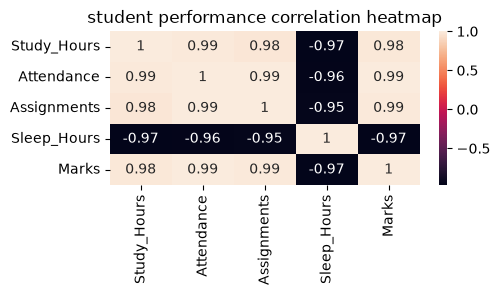

In [ ]:
plt.figure(figsize=(5,2))
sns.heatmap(corr,annot=True)
plt.title("student performance correlation heatmap")
plt.show()

In [13]:
marks_corr = corr["Marks"].drop("Marks")
ranking = marks_corr.abs().sort_values(ascending=False)


In [14]:
ranking

Attendance     0.993050
Assignments    0.990728
Study_Hours    0.981485
Sleep_Hours    0.973826
Name: Marks, dtype: float64

In [15]:
df["Marks"].max()


np.int64(95)

In [16]:
max_marks = df["Marks"].max()


In [17]:
df.drop(df["Marks"].idxmax())


,Study_Hours,Attendance,Assignments,Sleep_Hours,Marks
0,2,55,3,9,40
1,3,60,4,8,45
2,4,65,5,8,50
3,5,70,5,7,58
4,6,75,6,7,65
5,7,80,7,6,72
6,8,85,8,6,78
8,3,62,4,9,43
9,6,78,7,7,70
10,8,90,9,5,90


In [18]:
df1= df.drop(df["Marks"].idxmax())


In [21]:
df1.corr(method="pearson")

,Study_Hours,Attendance,Assignments,Sleep_Hours,Marks
Study_Hours,1.000000,0.987705,0.973238,-0.959100,0.977067
Attendance,0.987705,1.000000,0.990949,-0.952775,0.990149
Assignments,0.973238,0.990949,1.000000,-0.943161,0.987145
Sleep_Hours,-0.959100,-0.952775,-0.943161,1.000000,-0.969244
Marks,0.977067,0.990149,0.987145,-0.969244,1.000000


In [22]:
corr1 =  df1.corr(method="pearson")

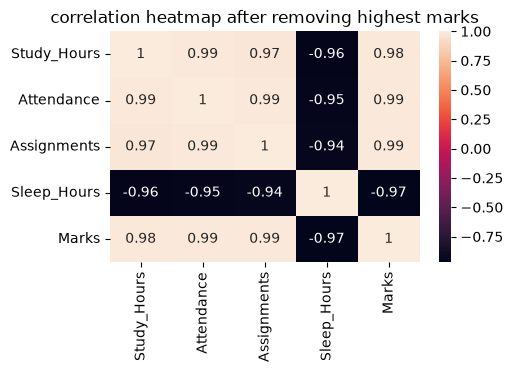

In [23]:
plt.figure(figsize=(5,3))
sns.heatmap(corr1,annot=True)
plt.title("correlation heatmap after removing highest marks")
plt.show()

In [24]:
before = df.corr()["Marks"].drop("Marks")
after = df1.corr()["Marks"].drop("Marks")
comparison = pd.DataFrame({"Before Removal": before,"After Removal": after})

In [25]:
comparison

,Before Removal,After Removal
Study_Hours,0.981485,0.977067
Attendance,0.993050,0.990149
Assignments,0.990728,0.987145
Sleep_Hours,-0.973826,-0.969244


Q2. Detecting Redundant Features in a Housing Dataset
A property company wants to investigate relationships among housing attributes before building a machine learning model.

(a) Generate a correlation matrix and heatmap. Programmatically identify unique feature pairs whose absolute correlation exceeds 0.90, excluding self-correlations and duplicate pairs. Explain why two highly correlated features may contain redundant information.

(b) Create two feature sets, one containing both area measurements and another containing only Area_sqft. Compare the feature relationships and explain why correlation can help identify redundancy but cannot, by itself, prove that removing a feature will improve a model.

In [26]:

df = pd.DataFrame({
    "Area_sqft": [800, 1000, 1200, 1400, 1600, 1800, 2000, 2200],
    "Area_sqm": [74.32, 92.90, 111.48, 130.06, 148.64, 167.22, 185.80, 204.38],
    "Bedrooms": [1, 2, 2, 3, 3, 3, 4, 4],
    "Age_Years": [25, 20, 18, 15, 12, 10, 8, 6],
    "Price_Lakhs": [25, 32, 38, 45, 52, 60, 68, 75]
})

In [27]:
df.corr(method="pearson")

,Area_sqft,Area_sqm,Bedrooms,Age_Years,Price_Lakhs
Area_sqft,1.000000,1.000000,0.957841,-0.990750,0.999184
Area_sqm,1.000000,1.000000,0.957841,-0.990750,0.999184
Bedrooms,0.957841,0.957841,1.000000,-0.969788,0.954819
Age_Years,-0.990750,-0.990750,-0.969788,1.000000,-0.986315
Price_Lakhs,0.999184,0.999184,0.954819,-0.986315,1.000000


In [28]:
corr = df.corr(method="pearson")

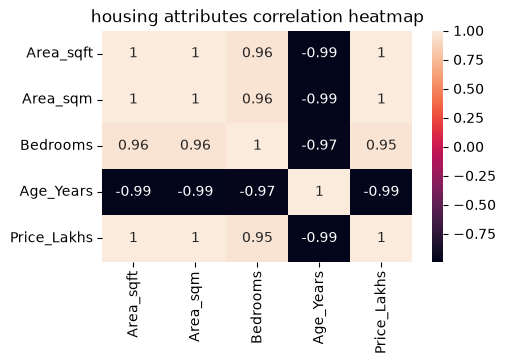

In [29]:
plt.figure(figsize=(5,3))
sns.heatmap(corr,annot=True)
plt.title("housing attributes correlation heatmap")
plt.show()